# Predicting the Men's March Madness Bracket

**CIS4930 Introduction to Machine Learning: Term Project**

**Team:** Lance, Sienna, Lincy, Pablo, Krish

**Contents**
1. Problem definition
2. Load the data
3. Data preparation
4. Exploratory data analysis
5. Project plan
6. Train / validation / test split
7. Models
8. Fit diagnosis (overfitting vs. underfitting)
9. Next steps and timeline

## 1. Problem Definition

**Question:** Can machine learning predict men's NCAA tournament games better than just picking the higher seed?

| | |
|---|---|
| **Task** | Supervised **binary classification** |
| **One row** | One men's NCAA tournament game (2003–2025) |
| **Team A / Team B** | Team A is the team with the lower ID, Team B the higher ID. This makes the label roughly 50/50 and means the label does not leak who won. |
| **Target** | `TeamA_Win`: 1 if Team A won, 0 if Team B won |
| **Features** | 13 numeric features, each one *Team A's regular-season value minus Team B's* |
| **Baseline** | Always pick the higher seed |
| **Metrics** | Accuracy, log loss (quality of the predicted probabilities), and precision / recall / F1 on **upsets** (games won by the worse seed) |

Every feature is calculated from **regular-season games or pre-tournament rankings only**, so nothing from the game being predicted leaks into the model.

## 2. Load the Data

Data: Kaggle *March Machine Learning Mania 2026* (built from official NCAA results). We use the men's files only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV, validation_curve, learning_curve
from sklearn.metrics import accuracy_score, log_loss, precision_score, recall_score, f1_score

import warnings
warnings.filterwarnings("ignore")

SEED = 42

# Plot style
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY = "#898781"
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e",
})

In [2]:
folder = "march-machine-learning-mania-2026/"

tourney = pd.read_csv(folder + "MNCAATourneyCompactResults.csv")     # tournament results
seeds   = pd.read_csv(folder + "MNCAATourneySeeds.csv")              # tournament seeds
season  = pd.read_csv(folder + "MRegularSeasonDetailedResults.csv")  # regular-season box scores
teams   = pd.read_csv(folder + "MTeams.csv")                         # team names
massey  = pd.read_csv(folder + "MMasseyOrdinals.csv")                # weekly computer rankings

for name, frame in [("Tournament games", tourney), ("Seeds", seeds), ("Regular season games", season),
                    ("Teams", teams), ("Rankings", massey)]:
    print(f"{name:22} {frame.shape}")

Tournament games       (2585, 8)
Seeds                  (2694, 3)
Regular season games   (124529, 34)
Teams                  (381, 4)
Rankings               (5865001, 5)


In [3]:
tourney.head()

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT
0,1985,136,1116,63,1234,54,N,0
1,1985,136,1120,59,1345,58,N,0
2,1985,136,1207,68,1250,43,N,0
3,1985,136,1229,58,1425,55,N,0
4,1985,136,1242,49,1325,38,N,0


Each row is one tournament game. `WTeamID` is the winner and `LTeamID` the loser. `DayNum` is the day of the season.

In [4]:
season.head()

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT,WFGM,WFGA,...,LFGA3,LFTM,LFTA,LOR,LDR,LAst,LTO,LStl,LBlk,LPF
0,2003,10,1104,68,1328,62,N,0,27,58,...,10,16,22,10,22,8,18,9,2,20
1,2003,10,1272,70,1393,63,N,0,26,62,...,24,9,20,20,25,7,12,8,6,16
2,2003,11,1266,73,1437,61,N,0,24,58,...,26,14,23,31,22,9,12,2,5,23
3,2003,11,1296,56,1457,50,N,0,18,38,...,22,8,15,17,20,9,19,4,3,23
4,2003,11,1400,77,1208,71,N,0,30,61,...,16,17,27,21,15,12,10,7,1,14


Regular-season box scores: `W` columns are the winner's stats and `L` columns the loser's. `WLoc` is the winner's location (H / A / N).

## 3. Data Preparation

### 3.1 Data quality

In [5]:
for name, frame in [("tourney", tourney), ("seeds", seeds), ("season", season), ("teams", teams), ("massey", massey)]:
    print(f"{name:8} missing values: {frame.isna().sum().sum():>3}   duplicates: {frame.duplicated().sum()}")

print()
print("Tournament seasons:", tourney.Season.min(), "to", tourney.Season.max())
print("Box score seasons: ", season.Season.min(), "to", season.Season.max())
print("No tournament in 2020:", 2020 not in tourney.Season.values)

tourney  missing values:   0   duplicates: 0
seeds    missing values:   0   duplicates: 0
season   missing values:   0   duplicates: 0
teams    missing values:   0   duplicates: 0
massey   missing values:   0   duplicates: 0

Tournament seasons: 1985 to 2025
Box score seasons:  2003 to 2026
No tournament in 2020: True


The data is clean: no missing values and no duplicates. Box scores only start in **2003**, so we use tournaments from 2003 onward. There was no tournament in 2020 (COVID).

### 3.2 Team season stats

For each team and season, we turn every regular-season game into one row per team, then average. We also estimate **possessions** per game (`FGA − OR + TO + 0.44·FTA`), which lets us measure scoring per 100 possessions so fast- and slow-paced teams can be compared fairly.

In [6]:
w = pd.DataFrame({"Season": season.Season, "TeamID": season.WTeamID, "OppID": season.LTeamID, "Win": 1,
                  "Points": season.WScore, "OppPoints": season.LScore,
                  "FGM": season.WFGM, "FGA": season.WFGA, "FGM3": season.WFGM3, "FGA3": season.WFGA3,
                  "Reb": season.WOR + season.WDR, "TO": season.WTO,
                  "FTA": season.WFTA, "OR": season.WOR,
                  "OppFGA": season.LFGA, "OppFTA": season.LFTA, "OppOR": season.LOR, "OppTO": season.LTO})

l = pd.DataFrame({"Season": season.Season, "TeamID": season.LTeamID, "OppID": season.WTeamID, "Win": 0,
                  "Points": season.LScore, "OppPoints": season.WScore,
                  "FGM": season.LFGM, "FGA": season.LFGA, "FGM3": season.LFGM3, "FGA3": season.LFGA3,
                  "Reb": season.LOR + season.LDR, "TO": season.LTO,
                  "FTA": season.LFTA, "OR": season.LOR,
                  "OppFGA": season.WFGA, "OppFTA": season.WFTA, "OppOR": season.WOR, "OppTO": season.WTO})

games = pd.concat([w, l])

# Estimated possessions for each team in each game
games["Poss"]    = games.FGA - games.OR + games.TO + 0.44 * games.FTA
games["OppPoss"] = games.OppFGA - games.OppOR + games.OppTO + 0.44 * games.OppFTA

t = games.groupby(["Season", "TeamID"]).sum()
n_games = games.groupby(["Season", "TeamID"]).size()

team = pd.DataFrame({
    "WinPct":  t.Win / n_games,
    "PPG":     t.Points / n_games,
    "OppPPG":  t.OppPoints / n_games,
    "FG_Pct":  t.FGM / t.FGA,
    "FG3_Pct": t.FGM3 / t.FGA3,
    "Reb":     t.Reb / n_games,
    "TO":      t.TO / n_games,
    "OffEff":  100 * t.Points / t.Poss,        # points scored per 100 possessions
    "DefEff":  100 * t.OppPoints / t.OppPoss,  # points allowed per 100 possessions
}).reset_index()
team["PointDiff"] = team.PPG - team.OppPPG

# Strength of schedule: average win % of the opponents each team played
opp_win = team.set_index(["Season", "TeamID"]).WinPct.rename("OppWinPct")
sos = games.join(opp_win, on=["Season", "OppID"]).groupby(["Season", "TeamID"]).OppWinPct.mean()
team = team.join(sos.rename("SOS"), on=["Season", "TeamID"])

# Pomeroy ranking: the last one published before the tournament starts (day 133)
pom = massey[(massey.SystemName == "POM") & (massey.RankingDayNum <= 133)]
pom = pom.sort_values("RankingDayNum").groupby(["Season", "TeamID"]).OrdinalRank.last()
team = team.join(pom.rename("Rank_POM"), on=["Season", "TeamID"])

# Seeds: "W01" -> region W, seed 1. "W16a" / "W16b" are First Four play-in teams.
seeds["Region"]  = seeds.Seed.str[0]
seeds["SeedNum"] = seeds.Seed.str[1:3].astype(int)
team = team.merge(seeds.rename(columns={"Seed": "SeedStr", "SeedNum": "Seed"}), on=["Season", "TeamID"], how="left")

print("Team-seasons:", len(team))
team.dropna(subset=["Seed"]).head()

Team-seasons: 8346


,Season,TeamID,WinPct,PPG,OppPPG,FG_Pct,FG3_Pct,Reb,TO,OffEff,DefEff,PointDiff,SOS,Rank_POM,SeedStr,Region,Seed
2,2003,1104,0.607143,69.285714,65.000000,0.420362,0.320144,37.500000,13.285714,104.817272,98.474191,4.285714,0.572492,33.0,Y10,Y,10.0
9,2003,1112,0.892857,85.214286,70.250000,0.461413,0.350534,42.821429,14.785714,111.651848,92.163955,14.964286,0.551868,3.0,Z01,Z,1.0
10,2003,1113,0.620690,75.965517,69.172414,0.478182,0.317808,37.000000,14.000000,110.514699,99.960136,6.793103,0.581878,32.0,Z10,Z,10.0
16,2003,1120,0.633333,70.100000,65.566667,0.469835,0.344898,34.500000,15.900000,104.084178,97.172272,4.533333,0.572247,45.0,W10,W,10.0
17,2003,1122,0.740741,69.703704,67.703704,0.452347,0.349138,34.851852,15.222222,103.684605,100.563331,2.000000,0.461247,123.0,W13,W,13.0


### 3.3 One row per tournament game

We put Team A and Team B side by side and take differences. We also label each game's **round** from the two teams' seeds. (Day numbers can't be used because the 2021 schedule was shifted.)

In [7]:
# Order of seeds down one region of the bracket: neighbours meet in round 1, pairs of neighbours in round 2, ...
BRACKET_ORDER = [1, 16, 8, 9, 5, 12, 4, 13, 6, 11, 3, 14, 7, 10, 2, 15]
POSITION = {s: i for i, s in enumerate(BRACKET_ORDER)}
ROUND_NAMES = {0: "First Four", 1: "Round of 64", 2: "Round of 32", 3: "Sweet 16",
               4: "Elite 8", 5: "Final Four", 6: "Championship"}

def get_round(seed_a, seed_b):
    region_a, region_b = seed_a[0], seed_b[0]
    num_a, num_b = int(seed_a[1:3]), int(seed_b[1:3])
    if region_a != region_b:
        same_semifinal = {region_a, region_b} in ({"W", "X"}, {"Y", "Z"})
        return 5 if same_semifinal else 6
    if num_a == num_b:
        return 0                                  # play-in game between two "16" seeds, etc.
    pa, pb = POSITION[num_a], POSITION[num_b]
    r = 1
    while pa // 2**r != pb // 2**r:
        r += 1
    return r

In [8]:
df = tourney[tourney.Season >= 2003].copy()
df["TeamA"] = df[["WTeamID", "LTeamID"]].min(axis=1)
df["TeamB"] = df[["WTeamID", "LTeamID"]].max(axis=1)
df["TeamA_Win"] = (df.WTeamID == df.TeamA).astype(int)

df = df.merge(team.add_prefix("A_"), left_on=["Season", "TeamA"], right_on=["A_Season", "A_TeamID"])
df = df.merge(team.add_prefix("B_"), left_on=["Season", "TeamB"], right_on=["B_Season", "B_TeamID"])

features = ["Seed", "WinPct", "PointDiff", "PPG", "OppPPG", "FG_Pct", "FG3_Pct", "Reb", "TO",
            "OffEff", "DefEff", "SOS", "Rank_POM"]
for f in features:
    df[f + "_Diff"] = df["A_" + f] - df["B_" + f]
feature_cols = [f + "_Diff" for f in features]

names = teams.set_index("TeamID").TeamName
df["TeamA_Name"] = df.TeamA.map(names)
df["TeamB_Name"] = df.TeamB.map(names)
df["Round"] = [get_round(a, b) for a, b in zip(df.A_SeedStr, df.B_SeedStr)]
df["RoundName"] = df.Round.map(ROUND_NAMES)

# Upset = the worse (higher-number) seed won. Games between equal seeds can't be upsets.
df["HigherSeedWon"] = np.where(df.Seed_Diff == 0, np.nan,
                               ((df.Seed_Diff < 0) == (df.TeamA_Win == 1)).astype(float))
df["Upset"] = 1 - df.HigherSeedWon

data = df[["Season", "Round", "RoundName", "TeamA_Name", "TeamB_Name", "A_Seed", "B_Seed"]
          + feature_cols + ["HigherSeedWon", "Upset", "TeamA_Win"]].reset_index(drop=True)

print("Rows (games):", len(data))
print("Features:", len(feature_cols))
print("Missing values in features:", data[feature_cols].isna().sum().sum())
print()
print(data.RoundName.value_counts().reindex(ROUND_NAMES.values()).to_string())
data.head()

Rows (games): 1449
Features: 13
Missing values in features: 0

RoundName
First Four       64
Round of 64     703
Round of 32     352
Sweet 16        176
Elite 8          88
Final Four       44
Championship     22


,Season,Round,RoundName,TeamA_Name,TeamB_Name,A_Seed,B_Seed,Seed_Diff,WinPct_Diff,PointDiff_Diff,...,FG3_Pct_Diff,Reb_Diff,TO_Diff,OffEff_Diff,DefEff_Diff,SOS_Diff,Rank_POM_Diff,HigherSeedWon,Upset,TeamA_Win
0,2003,0,First Four,TX Southern,UNC Asheville,16.0,16.0,0.0,0.151724,9.208046,...,-0.039433,2.518391,-0.973563,2.653173,-12.376875,-0.104891,-5.0,NaN,NaN,0
1,2003,1,Round of 64,Arizona,Vermont,1.0,16.0,-15.0,0.237685,10.309113,...,0.009777,4.131773,0.716749,8.258702,-4.352797,0.114559,-141.0,1.0,0.0,1
2,2003,1,Round of 64,Arizona St,Memphis,10.0,7.0,3.0,-0.172414,-1.896552,...,-0.030989,-3.034483,0.206897,3.754363,5.522507,0.065246,12.0,0.0,1.0,1
3,2003,1,Round of 64,C Michigan,Creighton,11.0,6.0,5.0,-0.085684,-8.805643,...,-0.008284,-0.198537,4.877743,-4.162118,8.874154,-0.005888,23.0,0.0,1.0,1
4,2003,1,Round of 64,California,NC State,8.0,9.0,-1.0,0.124138,0.324138,...,0.022444,3.854023,-0.027586,-2.338371,-2.831146,-0.031658,-8.0,1.0,0.0,1


The round labels match the tournament format: 32 Round-of-64 games, 16 Round-of-32 games and so on per year, plus the First Four games (4 per year since 2011, 1 per year before that).

**Features** (all are Team A minus Team B):

| Feature | Meaning |
|---|---|
| `Seed_Diff` | Tournament seed (1 = best) |
| `WinPct_Diff` | Regular-season win % |
| `PointDiff_Diff` | Average scoring margin |
| `PPG_Diff` / `OppPPG_Diff` | Points scored / allowed per game |
| `FG_Pct_Diff` / `FG3_Pct_Diff` | Field goal % / 3-point % |
| `Reb_Diff` / `TO_Diff` | Rebounds / turnovers per game |
| `OffEff_Diff` / `DefEff_Diff` | Points scored / allowed per 100 possessions |
| `SOS_Diff` | Strength of schedule (average win % of opponents) |
| `Rank_POM_Diff` | Pomeroy computer ranking before the tournament (1 = best) |

## 4. Exploratory Data Analysis

### 4.1 The target is balanced

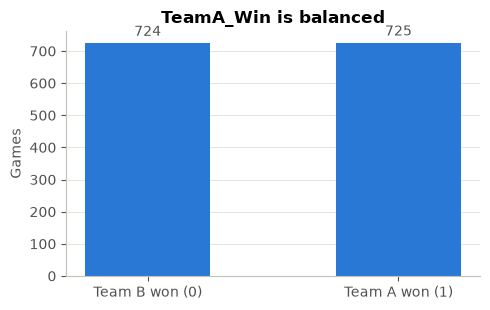

TeamA_Win
0    724
1    725


In [9]:
counts = data.TeamA_Win.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(["Team B won (0)", "Team A won (1)"], counts.values, color=BLUE, width=0.5)
ax.bar_label(bars, padding=3, color="#52514e")
ax.set_ylabel("Games")
ax.set_title("TeamA_Win is balanced")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(counts.to_string())

The two classes are almost exactly 50/50, so accuracy is a fair metric and we don't need class weighting or resampling.

### 4.2 How often does the higher seed win?

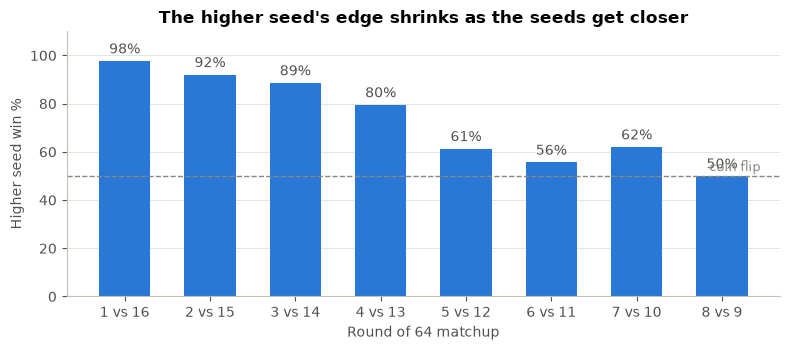

Higher seed wins 71.3% of all games with different seeds (n = 1367)


In [10]:
r64 = data[data.Round == 1].copy()
r64["Matchup"] = r64[["A_Seed", "B_Seed"]].min(axis=1).astype(int).astype(str) + " vs " + \
                 r64[["A_Seed", "B_Seed"]].max(axis=1).astype(int).astype(str)
order = [f"{s} vs {17 - s}" for s in range(1, 9)]
by_matchup = r64.groupby("Matchup").HigherSeedWon.mean().reindex(order) * 100

overall = data.HigherSeedWon.mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(order, by_matchup.values, color=BLUE, width=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=3, color="#52514e")
ax.axhline(50, color=GRAY, lw=1, ls="--")
ax.text(7.45, 52, "coin flip", color=GRAY, ha="right", fontsize=9)
ax.set_ylim(0, 110)
ax.set_ylabel("Higher seed win %")
ax.set_xlabel("Round of 64 matchup")
ax.set_title("The higher seed's edge shrinks as the seeds get closer")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"Higher seed wins {overall:.1f}% of all games with different seeds (n = {data.HigherSeedWon.notna().sum()})")

Seeds are very informative for lopsided matchups (1 vs 16, 2 vs 15) but close to a coin flip for 8 vs 9. **These close matchups are where a model could beat the seed baseline.**

### 4.3 Upsets by round and by year

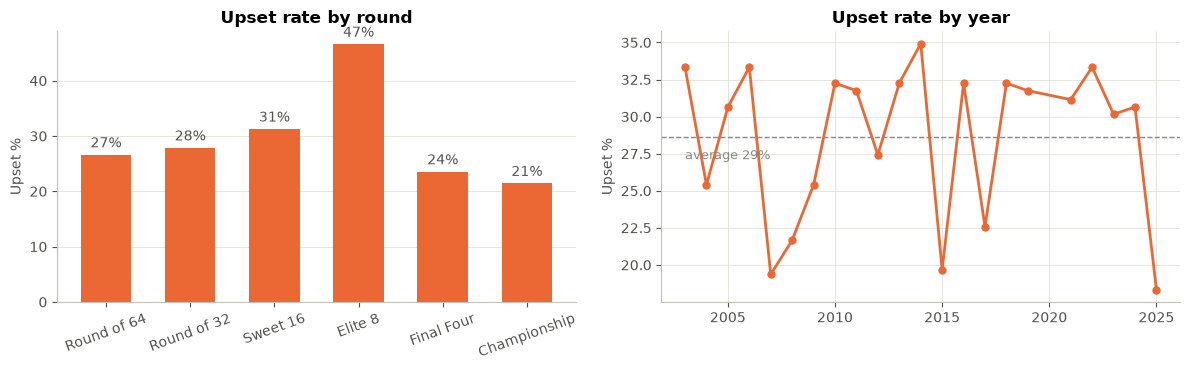

In [11]:
by_round = data.groupby("Round").Upset.mean().drop(0, errors="ignore") * 100   # First Four games are equal seeds
by_round.index = by_round.index.map(ROUND_NAMES)
by_year = data.groupby("Season").Upset.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bars = axes[0].bar(by_round.index, by_round.values, color=ORANGE, width=0.6)
axes[0].bar_label(bars, fmt="%.0f%%", padding=3, color="#52514e")
axes[0].set_ylabel("Upset %")
axes[0].set_title("Upset rate by round")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="x", visible=False)

axes[1].plot(by_year.index, by_year.values, color=ORANGE, lw=2, marker="o", ms=5)
axes[1].axhline(by_year.mean(), color=GRAY, lw=1, ls="--")
axes[1].text(2003, by_year.mean() - 1.5, f"average {by_year.mean():.0f}%", color=GRAY, ha="left", fontsize=9)
axes[1].set_ylabel("Upset %")
axes[1].set_title("Upset rate by year")
plt.tight_layout()
plt.show()

About **29%** of games with different seeds are upsets, but the rate swings from 18% to 35% between years, so a single season is a noisy test. The Elite 8 has the highest upset rate (47%) because by then the seeds are close (often a 1 vs. a 2), so an upset there is close to a coin flip.

### 4.4 Feature distributions

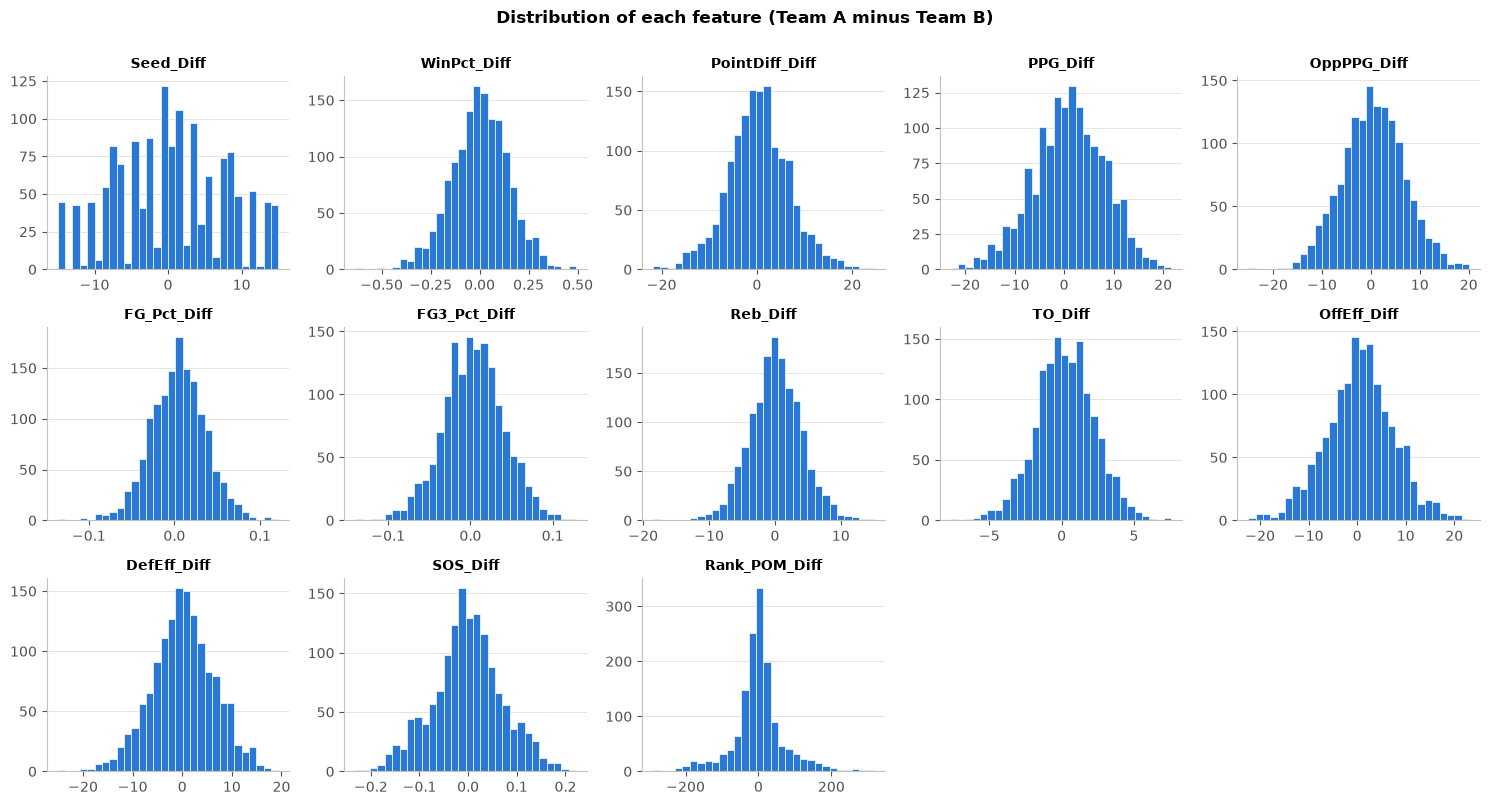

,count,mean,std,min,25%,50%,75%,max
Seed_Diff,1449.0,-0.108,7.474,-15.000,-5.000,0.000,5.000,15.000
WinPct_Diff,1449.0,0.002,0.145,-0.633,-0.088,0.001,0.097,0.492
PointDiff_Diff,1449.0,0.377,6.510,-21.790,-3.807,0.205,4.414,24.487
PPG_Diff,1449.0,0.882,7.241,-22.893,-3.795,1.000,5.952,21.643
OppPPG_Diff,1449.0,0.505,6.379,-25.036,-3.697,0.463,4.843,20.049
FG_Pct_Diff,1449.0,0.004,0.032,-0.136,-0.017,0.005,0.025,0.121
FG3_Pct_Diff,1449.0,0.004,0.037,-0.140,-0.020,0.003,0.027,0.128
Reb_Diff,1449.0,0.103,3.940,-18.500,-2.432,0.083,2.672,14.987
TO_Diff,1449.0,0.238,2.037,-7.667,-1.088,0.196,1.594,7.581
OffEff_Diff,1449.0,0.534,7.008,-22.421,-3.864,0.604,4.959,23.029


In [12]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for ax, col in zip(axes.flat, feature_cols):
    ax.hist(data[col], bins=30, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(col, fontsize=10)
    ax.grid(axis="x", visible=False)
for ax in axes.flat[len(feature_cols):]:
    ax.axis("off")
fig.suptitle("Distribution of each feature (Team A minus Team B)", fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

data[feature_cols].describe().T.round(3)

All features are roughly symmetric around 0, which is expected because Team A vs Team B is assigned by ID, not by strength. The features are on **very different scales** (e.g. `FG_Pct_Diff` is around ±0.1 while `Rank_POM_Diff` is around ±300), so we need to **standardize** them before logistic regression and KNN.

### 4.5 How each feature relates to winning

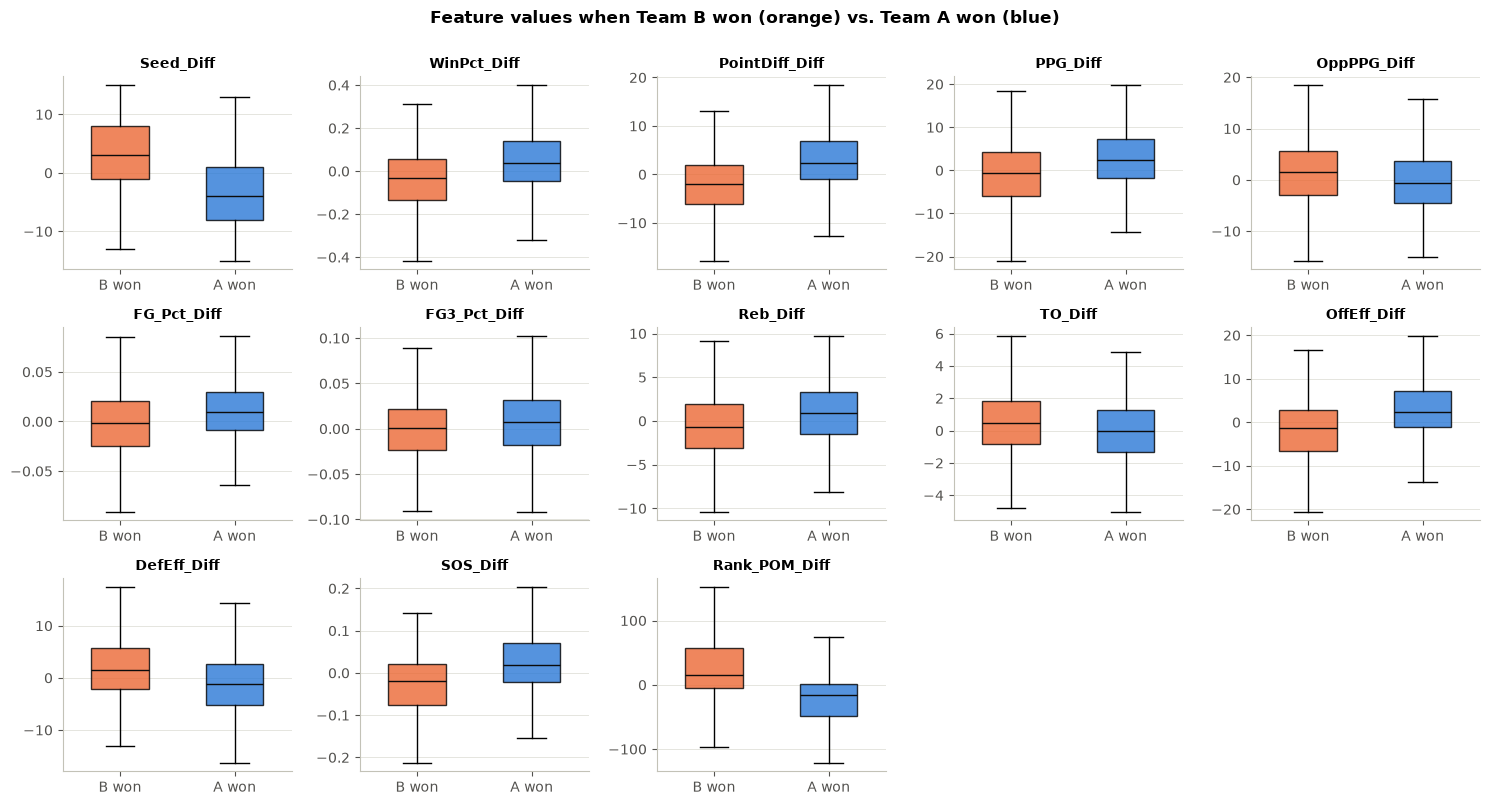

In [13]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for ax, col in zip(axes.flat, feature_cols):
    parts = [data.loc[data.TeamA_Win == 0, col], data.loc[data.TeamA_Win == 1, col]]
    bp = ax.boxplot(parts, widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color="#0b0b0b"))
    for patch, c in zip(bp["boxes"], [ORANGE, BLUE]):
        patch.set_facecolor(c); patch.set_alpha(0.8)
    ax.set_xticks([1, 2], ["B won", "A won"])
    ax.set_title(col, fontsize=10)
    ax.grid(axis="x", visible=False)
for ax in axes.flat[len(feature_cols):]:
    ax.axis("off")
fig.suptitle("Feature values when Team B won (orange) vs. Team A won (blue)", fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

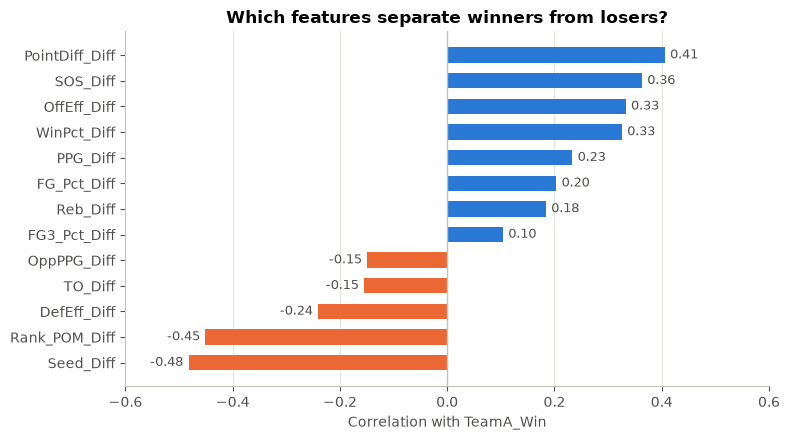

In [14]:
corr_target = data[feature_cols].corrwith(data.TeamA_Win).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [ORANGE if v < 0 else BLUE for v in corr_target.values]
ax.barh(corr_target.index, corr_target.values, color=colors, height=0.6)
ax.axvline(0, color="#c3c2b7", lw=1)
for i, v in enumerate(corr_target.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color="#52514e")
ax.set_xlim(-0.6, 0.6)
ax.set_xlabel("Correlation with TeamA_Win")
ax.set_title("Which features separate winners from losers?")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Features where **lower is better** (seed, Pomeroy rank, points allowed, defensive efficiency, turnovers) correlate negatively with winning, and features where higher is better correlate positively. This matches basketball intuition and is a good sanity check on the data.

### 4.6 Win probability vs. seed difference and Pomeroy rank difference

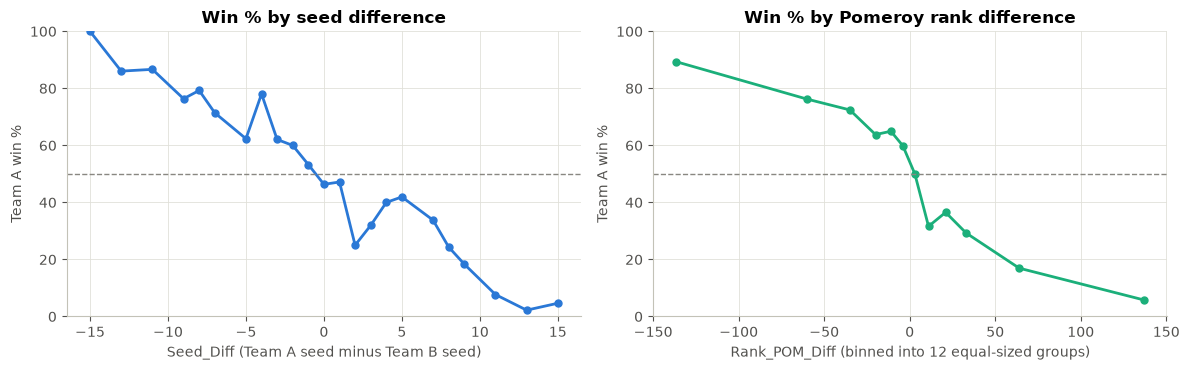

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

seed_rate = data.groupby("Seed_Diff").TeamA_Win.agg(["mean", "size"])
seed_rate = seed_rate[seed_rate["size"] >= 10]
axes[0].plot(seed_rate.index, seed_rate["mean"] * 100, color=BLUE, lw=2, marker="o", ms=5)
axes[0].set_xlabel("Seed_Diff (Team A seed minus Team B seed)")
axes[0].set_ylabel("Team A win %")
axes[0].set_title("Win % by seed difference")

bins = pd.qcut(data.Rank_POM_Diff, 12)
pom_rate = data.groupby(bins, observed=True).agg(x=("Rank_POM_Diff", "median"), y=("TeamA_Win", "mean"))
axes[1].plot(pom_rate.x, pom_rate.y * 100, color=AQUA, lw=2, marker="o", ms=5)
axes[1].set_xlabel("Rank_POM_Diff (binned into 12 equal-sized groups)")
axes[1].set_ylabel("Team A win %")
axes[1].set_title("Win % by Pomeroy rank difference")

for ax in axes:
    ax.axhline(50, color=GRAY, lw=1, ls="--")
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

Both relationships are smooth and S-shaped: the bigger the gap, the more likely the better team wins. This shape is exactly what **logistic regression** models, which is why it is a natural first model.

### 4.7 Correlation between features

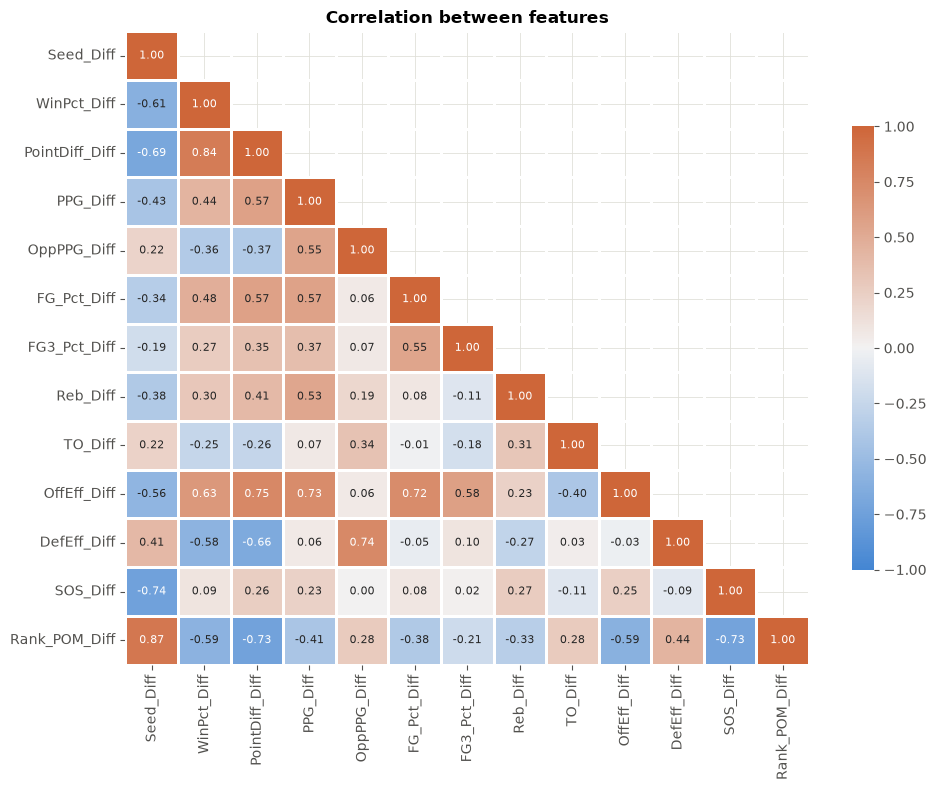

Most correlated feature pairs:
Seed_Diff       Rank_POM_Diff     0.87
WinPct_Diff     PointDiff_Diff    0.84
PointDiff_Diff  OffEff_Diff       0.75
Seed_Diff       SOS_Diff          0.74
OppPPG_Diff     DefEff_Diff       0.74
PointDiff_Diff  Rank_POM_Diff     0.73


In [16]:
corr = data[feature_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cmap = sns.diverging_palette(250, 25, s=80, l=55, center="light", as_cmap=True)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation between features")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
print("Most correlated feature pairs:")
print(pairs.abs().sort_values(ascending=False).head(6).round(2).to_string())

Several features overlap heavily: point differential, win %, seed and Pomeroy rank all measure overall team strength, and points per game moves with offensive efficiency. This **multicollinearity** makes logistic regression coefficients hard to interpret individually and is a reason to try regularization and feature selection.

### 4.8 Outliers

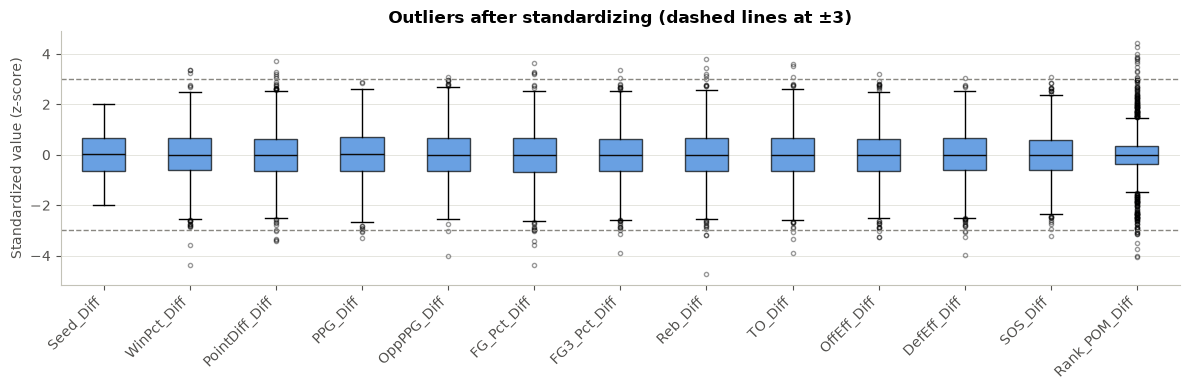

Games with |z| > 3:
Rank_POM_Diff     22
PointDiff_Diff     9
FG_Pct_Diff        8
Reb_Diff           8
TO_Diff            6
DefEff_Diff        5
WinPct_Diff        5
OffEff_Diff        4
FG3_Pct_Diff       4
PPG_Diff           3
OppPPG_Diff        3
SOS_Diff           2


In [17]:
z = (data[feature_cols] - data[feature_cols].mean()) / data[feature_cols].std()
outliers = (z.abs() > 3).sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 4))
bp = ax.boxplot([z[c] for c in feature_cols], widths=0.5, patch_artist=True,
                medianprops=dict(color="#0b0b0b"), flierprops=dict(marker="o", ms=3, alpha=0.4))
for patch in bp["boxes"]:
    patch.set_facecolor(BLUE); patch.set_alpha(0.7)
ax.set_xticks(range(1, len(feature_cols) + 1), feature_cols, rotation=45, ha="right")
ax.axhline(3, color=GRAY, ls="--", lw=1); ax.axhline(-3, color=GRAY, ls="--", lw=1)
ax.set_ylabel("Standardized value (z-score)")
ax.set_title("Outliers after standardizing (dashed lines at ±3)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print("Games with |z| > 3:")
print(outliers[outliers > 0].to_string())

In [18]:
# The most extreme games are real mismatches, not data errors
cols = ["Season", "RoundName", "TeamA_Name", "A_Seed", "TeamB_Name", "B_Seed", "PointDiff_Diff", "Rank_POM_Diff", "TeamA_Win"]
data.loc[data.PointDiff_Diff.abs().sort_values(ascending=False).index[:5], cols]

,Season,RoundName,TeamA_Name,A_Seed,TeamB_Name,B_Seed,PointDiff_Diff,Rank_POM_Diff,TeamA_Win
922,2017,Round of 64,Gonzaga,1.0,S Dakota St,16.0,24.486742,-186.0,1
790,2015,Round of 64,Hampton,16.0,Kentucky,1.0,-21.789661,249.0,0
155,2005,Round of 64,North Carolina,1.0,Oakland,16.0,21.654060,-171.0,1
1056,2019,Round of 64,F Dickinson,16.0,Gonzaga,1.0,-21.529814,206.0,0
1188,2022,Round of 64,Georgia St,16.0,Gonzaga,1.0,-21.402759,151.0,0


Only a small number of games are more than 3 standard deviations out, and they are real games (usually a dominant team against a weak play-in or small-conference team), not recording errors. We **keep them**: removing real mismatches would make the model worse at exactly the games that are easiest to predict. Standardizing limits their effect on logistic regression, and random forests are not sensitive to extreme values.

### 4.9 EDA takeaways

- **1,449 games, 13 features, no missing values, balanced target** (725 vs. 724).
- **The seed baseline is strong:** the higher seed wins **71.3%** of the time, from 98% in 1 vs. 16 games down to 50% in 8 vs. 9 games.
- **Upsets are common (about 29%) and vary a lot by year**, so we evaluate on whole seasons and use cross-validation instead of trusting one season.
- **The strongest single features measure overall team strength:** seed (r = −0.48), Pomeroy rank (−0.45), point differential (0.41) and strength of schedule (0.36). Shooting, rebounding and turnovers are weaker on their own.
- **Several features overlap heavily** (seed vs. Pomeroy rank r = 0.87, win % vs. point differential r = 0.84), so regularization and feature selection matter.
- **Outliers are real mismatches** and are kept. Features are on very different scales, so we standardize them.

## 5. Project Plan

| Step | What we do |
|---|---|
| **Data** | Regular-season box scores + seeds + Pomeroy rankings → 13 difference features per tournament game |
| **Split** | By season (not random): train 2003–2018, validate 2019 & 2021, test 2022–2025 |
| **Models** | Seed baseline → logistic regression → random forest → KNN → gradient boosting |
| **Tuning** | Grouped cross-validation by season on the training years |
| **Evaluation** | Accuracy, log loss, upset precision / recall / F1, and correct picks in a full simulated bracket |
| **Final test** | Each model scored once on 2022–2025 at the end of the project |

**Work split**

| Member | Responsibility |
|---|---|
| Lance | Coordination, seed baseline, bracket simulation |
| Sienna | Data cleaning and feature engineering |
| Lincy | Logistic regression |
| Pablo | KNN and random forest |
| Krish | Gradient boosting and evaluation |

## 6. Train / Validation / Test Split

We split **by season**, not randomly. The same schools appear every year and a random split would let the model train on games played *after* the games it is tested on. Splitting by season mirrors the real use: train on the past, predict a new tournament.

| Set | Seasons | Purpose |
|---|---|---|
| Train | 2003–2018 | Fit models and tune hyperparameters with season-grouped cross-validation |
| Validation | 2019, 2021 | Compare models and diagnose fit |
| Test | 2022–2025 | **Held out.** Used once, at the end, for the final results |

In [19]:
train = data[data.Season <= 2018]
val   = data[data.Season.isin([2019, 2021])]
test  = data[data.Season >= 2022]

X_train, y_train = train[feature_cols], train.TeamA_Win
X_val,   y_val   = val[feature_cols],   val.TeamA_Win
X_test,  y_test  = test[feature_cols],  test.TeamA_Win
groups = train.Season    # used so cross-validation folds never split a season

# Fit the scaler on training data only, so no information from validation/test leaks in
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:10} {len(part):5} games   seasons {part.Season.min()}–{part.Season.max()}   "
          f"Team A win rate {part.TeamA_Win.mean():.2f}")

Train       1048 games   seasons 2003–2018   Team A win rate 0.49
Validation   133 games   seasons 2019–2021   Team A win rate 0.46
Test         268 games   seasons 2022–2025   Team A win rate 0.57


**Leakage checks**
- Every feature comes from regular-season games or a ranking published before day 133 (before the tournament).
- The scaler and every hyperparameter are fit on the training seasons only.
- Cross-validation uses `GroupKFold` by season, so a fold never trains and validates on the same tournament.
- The test seasons are not touched in this notebook except to record their size.

## 7. Models

We use one helper to score every model the same way. An **upset pick** means the model picks the worse seed to win. Upset precision is "when we predicted an upset, how often did it happen?" and upset recall is "of the real upsets, how many did we catch?"

In [20]:
cv = GroupKFold(n_splits=5)
results = {}    # model name -> scores

def upset_scores(frame, pred):
    """Precision / recall / F1 for upset picks, on games where the two seeds differ."""
    m = frame.Seed_Diff.values != 0
    team_a_worse = frame.Seed_Diff.values[m] > 0
    actual = frame.Upset.values[m].astype(int)
    predicted = (pred[m] == 1) == team_a_worse      # picked the worse seed
    return (precision_score(actual, predicted, zero_division=0),
            recall_score(actual, predicted, zero_division=0),
            f1_score(actual, predicted, zero_division=0),
            int(predicted.sum()), int(actual.sum()))

def evaluate(name, p_train, p_val, cv_acc=np.nan):
    """p_train / p_val are predicted probabilities that Team A wins."""
    pred_train, pred_val = (p_train >= 0.5).astype(int), (p_val >= 0.5).astype(int)
    prec, rec, f1, n_pred, n_actual = upset_scores(val, pred_val)
    row = {
        "Model": name,
        "Train acc": accuracy_score(y_train, pred_train),
        "CV acc": cv_acc,
        "Val acc": accuracy_score(y_val, pred_val),
        "Train log loss": log_loss(y_train, np.clip(p_train, 1e-3, 1 - 1e-3)),
        "Val log loss": log_loss(y_val, np.clip(p_val, 1e-3, 1 - 1e-3)),
        "Upset precision": prec, "Upset recall": rec, "Upset F1": f1,
        "Upsets picked": n_pred, "Actual upsets": n_actual,
    }
    results[name] = row
    return pd.Series(row).drop("Model")

### 7.1 Seed baseline

Pick the higher seed. When both teams have the same seed (First Four and some Final Four games) we have no information, so the baseline gives each team 50%.

In [21]:
def seed_baseline(frame):
    return np.where(frame.Seed_Diff < 0, 1.0, np.where(frame.Seed_Diff > 0, 0.0, 0.5))

evaluate("Seed baseline", seed_baseline(train), seed_baseline(val)).to_frame("Seed baseline").round(3)

,Seed baseline
Train acc,0.700382
CV acc,NaN
Val acc,0.684211
Train log loss,1.901092
Val log loss,2.073126
Upset precision,0.0
Upset recall,0.0
Upset F1,0.0
Upsets picked,0
Actual upsets,39


The baseline's log loss is high because it is 100% confident on every pick, so each upset is penalized heavily. Accuracy is the number to beat. Being right about 70% of the time and **never picking an upset** is the bar.

### 7.2 Logistic regression

We tune the regularization strength `C` (smaller = stronger regularization) with season-grouped cross-validation on the training years.

In [22]:
lr_search = GridSearchCV(
    LogisticRegression(max_iter=2000),
    {"C": np.logspace(-3, 2, 11)},
    cv=cv, scoring="neg_log_loss",
)
lr_search.fit(X_train_s, y_train, groups=groups)
lr = lr_search.best_estimator_

lr_cv_acc = GridSearchCV(LogisticRegression(C=lr.C, max_iter=2000), {}, cv=cv, scoring="accuracy") \
    .fit(X_train_s, y_train, groups=groups).best_score_

print("Best C:", round(lr.C, 4))
evaluate("Logistic regression", lr.predict_proba(X_train_s)[:, 1], lr.predict_proba(X_val_s)[:, 1],
         lr_cv_acc).to_frame("Logistic regression").round(3)

Best C: 0.0316


,Logistic regression
Train acc,0.714695
CV acc,0.707245
Val acc,0.676692
Train log loss,0.536121
Val log loss,0.570795
Upset precision,0.375
Upset recall,0.076923
Upset F1,0.12766
Upsets picked,8
Actual upsets,39


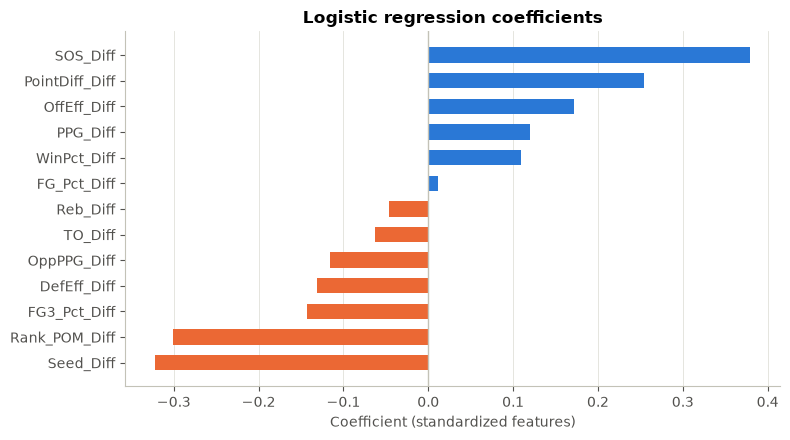

In [23]:
coefs = pd.Series(lr.coef_[0], index=feature_cols).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(coefs.index, coefs.values, color=[ORANGE if v < 0 else BLUE for v in coefs.values], height=0.6)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_xlabel("Coefficient (standardized features)")
ax.set_title("Logistic regression coefficients")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Cross-validation picked strong regularization (`C` ≈ 0.03), which shrinks the overlapping features toward each other. The largest effects are strength of schedule, seed, Pomeroy rank and point differential, the same features the EDA flagged. Because the features are correlated, individual coefficients should not be over-interpreted. For example, `FG3_Pct_Diff` gets a small negative coefficient even though it is positively correlated with winning on its own.

### 7.3 Random forest

A random forest can capture non-linear effects and interactions between features. With only about 1,000 training games, a fully grown forest will memorize the training data, so we tune the tree depth and the minimum leaf size.

In [24]:
rf_search = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    {"max_depth": [2, 3, 4, 6, 8, None], "min_samples_leaf": [1, 5, 20, 50]},
    cv=cv, scoring="neg_log_loss",
)
rf_search.fit(X_train, y_train, groups=groups)     # trees don't need scaled features
rf = rf_search.best_estimator_

rf_cv_acc = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1,
                                                **rf_search.best_params_),
                         {}, cv=cv, scoring="accuracy").fit(X_train, y_train, groups=groups).best_score_

print("Best parameters:", rf_search.best_params_)
evaluate("Random forest", rf.predict_proba(X_train)[:, 1], rf.predict_proba(X_val)[:, 1],
         rf_cv_acc).to_frame("Random forest").round(3)

Best parameters: {'max_depth': 6, 'min_samples_leaf': 20}


,Random forest
Train acc,0.765267
CV acc,0.704391
Val acc,0.706767
Train log loss,0.480976
Val log loss,0.567968
Upset precision,0.571429
Upset recall,0.102564
Upset F1,0.173913
Upsets picked,7
Actual upsets,39


In [25]:
# Untuned forest (fully grown trees) for comparison
rf_full = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
rf_full_cv = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                          {}, cv=cv, scoring="accuracy").fit(X_train, y_train, groups=groups).best_score_
evaluate("Random forest (untuned)", rf_full.predict_proba(X_train)[:, 1], rf_full.predict_proba(X_val)[:, 1],
         rf_full_cv).to_frame("Random forest (untuned)").round(3)

,Random forest (untuned)
Train acc,1.0
CV acc,0.70879
Val acc,0.684211
Train log loss,0.155959
Val log loss,0.575483
Upset precision,0.615385
Upset recall,0.205128
Upset F1,0.307692
Upsets picked,13
Actual upsets,39


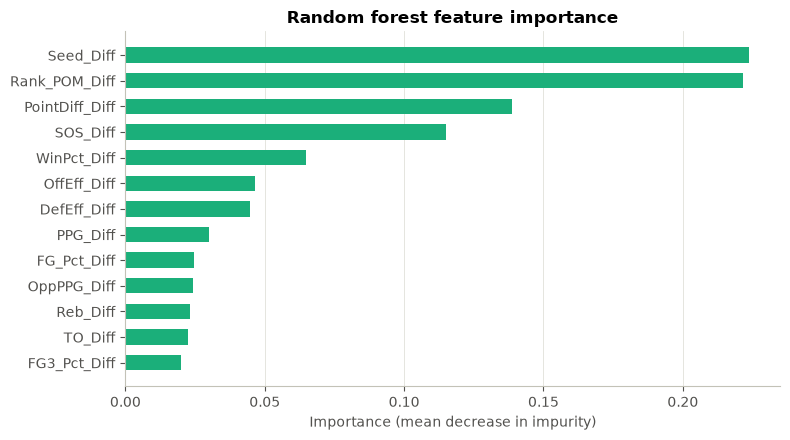

In [26]:
importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance.values, color=AQUA, height=0.6)
ax.set_xlabel("Importance (mean decrease in impurity)")
ax.set_title("Random forest feature importance")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

The forest agrees with logistic regression: **seed and Pomeroy rank** (about 0.22 each) are by far the most important, followed by point differential and strength of schedule. Every box-score stat is below 0.07. Overall-strength measures carry almost all of the signal.

### 7.4 Results so far

In [27]:
results_df = pd.DataFrame(results.values()).set_index("Model")
results_df.round(3)

,Train acc,CV acc,Val acc,Train log loss,Val log loss,Upset precision,Upset recall,Upset F1,Upsets picked,Actual upsets
Model,,,,,,,,,,
Seed baseline,0.700,NaN,0.684,1.901,2.073,0.000,0.000,0.000,0,39
Logistic regression,0.715,0.707,0.677,0.536,0.571,0.375,0.077,0.128,8,39
Random forest,0.765,0.704,0.707,0.481,0.568,0.571,0.103,0.174,7,39
Random forest (untuned),1.000,0.709,0.684,0.156,0.575,0.615,0.205,0.308,13,39


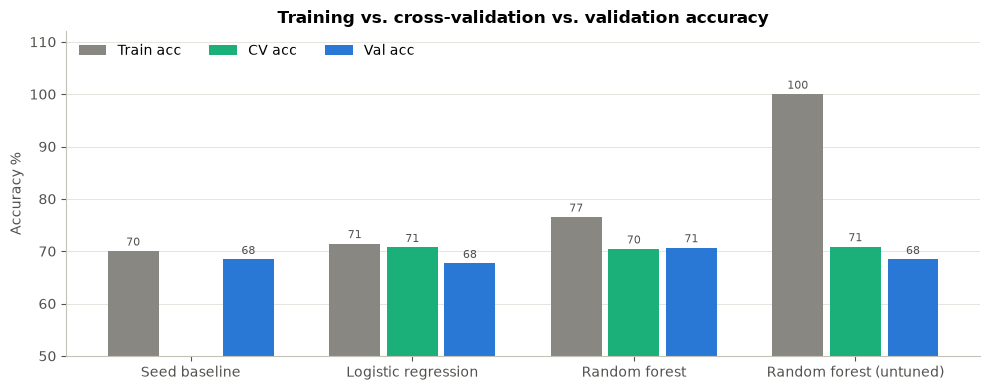

In [28]:
plot_df = results_df[["Train acc", "CV acc", "Val acc"]]
x = np.arange(len(plot_df))
width = 0.26

fig, ax = plt.subplots(figsize=(10, 4))
for i, (col, c) in enumerate(zip(plot_df.columns, [GRAY, AQUA, BLUE])):
    bars = ax.bar(x + (i - 1) * width, plot_df[col].values * 100, width - 0.03, color=c, label=col)
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=8, color="#52514e")
ax.set_xticks(x, plot_df.index)
ax.set_ylim(50, 112)
ax.set_ylabel("Accuracy %")
ax.set_title("Training vs. cross-validation vs. validation accuracy")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What the results show**

- **Accuracy:** all models land close to the seed baseline. On the 133 validation games, the tuned random forest is best (70.7% vs. 68.4% for the baseline), which is **3 more correct games**. In cross-validation over 16 training seasons, both models score about 70.5–70.7%, again close to the baseline's 70.0%. With only 133 validation games, one game is worth 0.75 points, so these gaps are not yet conclusive.
- **Probability quality:** this is where the models clearly win. Their log loss is about **0.57 vs. 2.07** for the baseline. The baseline is 100% confident on every pick, while the models give sensible probabilities (e.g. 60% for a close game). These probabilities are what we need for the bracket simulation.
- **Upsets:** the baseline never picks an upset (recall 0). The models pick a few: the tuned forest picked 7 upsets and 4 happened (57% precision), but it caught only 10% of the 39 real upsets. Picking upsets is hard, and improving it is a main goal for the rest of the project.

## 8. Fit Diagnosis: Overfitting or Underfitting?

We check fit three ways:
1. **Train vs. validation gap** (table above). A large gap means overfitting.
2. **Validation curves**: how train and cross-validation scores change with model complexity.
3. **Learning curves**: how scores change with more training data.

### 8.1 Validation curves

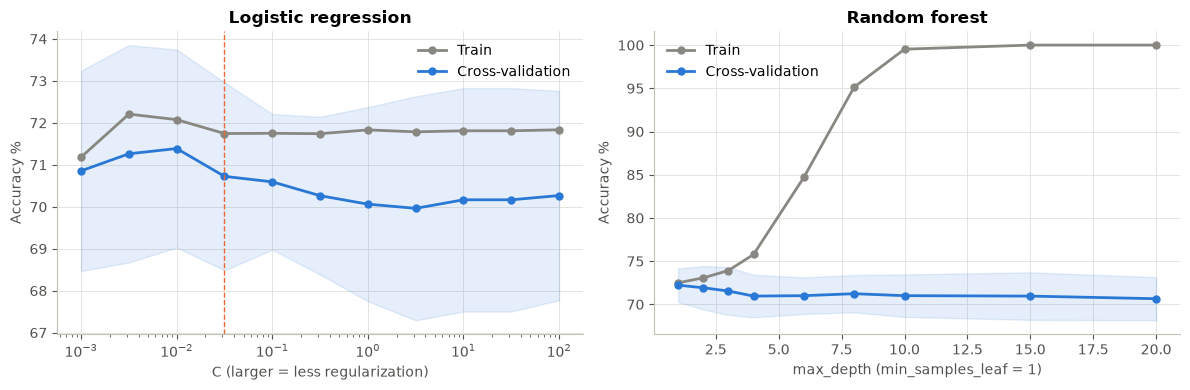

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

C_range = np.logspace(-3, 2, 11)
tr, va = validation_curve(LogisticRegression(max_iter=2000), X_train_s, y_train, groups=groups,
                          param_name="C", param_range=C_range, cv=cv, scoring="accuracy")
axes[0].semilogx(C_range, tr.mean(1) * 100, color=GRAY, lw=2, marker="o", ms=5, label="Train")
axes[0].semilogx(C_range, va.mean(1) * 100, color=BLUE, lw=2, marker="o", ms=5, label="Cross-validation")
axes[0].fill_between(C_range, (va.mean(1) - va.std(1)) * 100, (va.mean(1) + va.std(1)) * 100, color=BLUE, alpha=0.12)
axes[0].axvline(lr.C, color=ORANGE, ls="--", lw=1)
axes[0].set_xlabel("C (larger = less regularization)")
axes[0].set_title("Logistic regression")

depths = [1, 2, 3, 4, 6, 8, 10, 15, 20]
tr, va = validation_curve(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1,
                                                 min_samples_leaf=1),
                          X_train, y_train, groups=groups, param_name="max_depth", param_range=depths,
                          cv=cv, scoring="accuracy")
axes[1].plot(depths, tr.mean(1) * 100, color=GRAY, lw=2, marker="o", ms=5, label="Train")
axes[1].plot(depths, va.mean(1) * 100, color=BLUE, lw=2, marker="o", ms=5, label="Cross-validation")
axes[1].fill_between(depths, (va.mean(1) - va.std(1)) * 100, (va.mean(1) + va.std(1)) * 100, color=BLUE, alpha=0.12)
axes[1].set_xlabel("max_depth (min_samples_leaf = 1)")
axes[1].set_title("Random forest")

for ax in axes:
    ax.set_ylabel("Accuracy %")
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **Logistic regression:** train and cross-validation accuracy stay within about 1–2 points at every `C`. **No overfitting.** Both sit around 70–72%, which suggests a ceiling caused by the information in the features and the randomness of single games (mild underfitting / high bias), not by the model.
- **Random forest:** once trees are deeper than about 4, training accuracy climbs to **100%** while cross-validation accuracy stays at about 71%. That is **clear overfitting**: deep trees memorize the training games. Shallow trees do just as well on unseen seasons, which is why tuning limits the depth and requires at least 20 games per leaf.

### 8.2 Learning curves

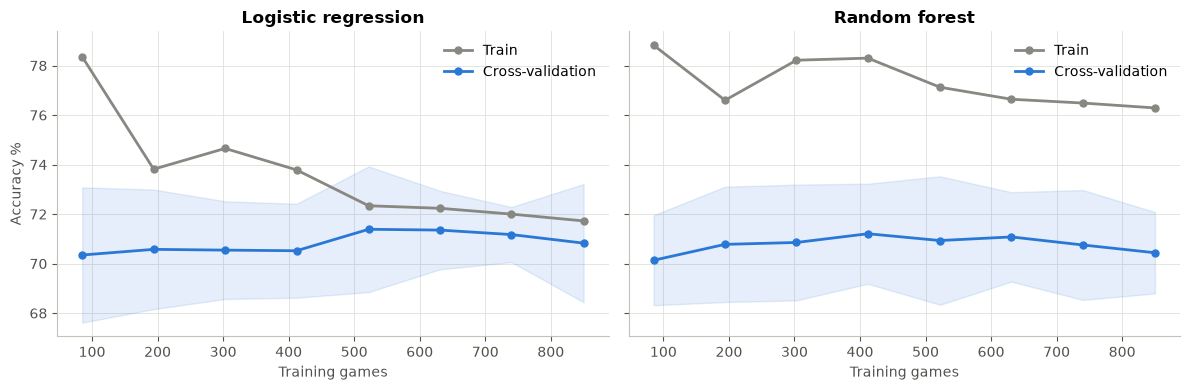

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
models = [("Logistic regression", lr, X_train_s), ("Random forest", rf, X_train)]
for ax, (name, model, X) in zip(axes, models):
    sizes, tr, va = learning_curve(model, X, y_train, groups=groups, cv=cv, scoring="accuracy",
                                   train_sizes=np.linspace(0.1, 1.0, 8))
    ax.plot(sizes, tr.mean(1) * 100, color=GRAY, lw=2, marker="o", ms=5, label="Train")
    ax.plot(sizes, va.mean(1) * 100, color=BLUE, lw=2, marker="o", ms=5, label="Cross-validation")
    ax.fill_between(sizes, (va.mean(1) - va.std(1)) * 100, (va.mean(1) + va.std(1)) * 100, color=BLUE, alpha=0.12)
    ax.set_xlabel("Training games")
    ax.set_title(name)
    ax.legend(frameon=False)
axes[0].set_ylabel("Accuracy %")
plt.tight_layout()
plt.show()

- **Logistic regression:** training accuracy drops from 78% to 72% as data grows and cross-validation accuracy stays at about 71%. The two curves **meet by about 500 games**, so more games of the same kind will not help much. Gains have to come from better features or a better way of using the probabilities.
- **Random forest:** a gap of about 5–6 points remains between the curves even with all training data. The tuned forest still has some variance, so stronger regularization (or gradient boosting with early stopping) is worth trying.

### 8.3 Accuracy by validation season

In [31]:
by_season = pd.DataFrame({
    "Games": val.groupby("Season").size(),
    "Seed baseline": val.assign(p=(seed_baseline(val) >= 0.5).astype(int) == val.TeamA_Win).groupby("Season").p.mean(),
    "Logistic regression": val.assign(p=lr.predict(X_val_s) == y_val).groupby("Season").p.mean(),
    "Random forest": val.assign(p=rf.predict(X_val) == y_val).groupby("Season").p.mean(),
})
by_season.round(3)

,Games,Seed baseline,Logistic regression,Random forest
Season,,,,
2019,67,0.701,0.701,0.731
2021,66,0.667,0.652,0.682


### 8.4 Fit summary

| Model | Train acc | CV acc | Val acc | Diagnosis |
|---|---|---|---|---|
| Logistic regression | 71.5% | 70.7% | 67.7% | **Good fit.** Small train/CV gap. Limited by the features (slight underfit) |
| Random forest (tuned) | 76.5% | 70.4% | 70.7% | **Slight overfitting**, controlled by depth 6 and min 20 games per leaf |
| Random forest (untuned) | 100% | 70.9% | 68.4% | **Overfitting.** It memorizes the training games |

Validation accuracy changes by several points between the two seasons (e.g. random forest: 73.1% in 2019 vs. 68.2% in 2021), which confirms that one or two seasons are a noisy estimate. **Cross-validation across 16 seasons is our main tool for model selection**, and 2022–2025 (268 games) is kept for the final test.

**Proposed solutions based on these results**
1. **Reduce overlapping features:** drop redundant features (e.g. win % vs. point differential, PPG vs. offensive efficiency) or use L1 (lasso) regularization to select them automatically.
2. **Double the training data by swapping teams:** add each game a second time with Team A and Team B swapped (all features × −1, label flipped). This also removes any bias from Team A always being the lower ID.
3. **Regularize tree models more** and try gradient boosting with early stopping.
4. **Tune an upset threshold:** pick the underdog when its predicted win probability is above a cutoff tuned in cross-validation, trading some accuracy for more upset picks.
5. **Evaluate on full brackets**, where early mistakes carry forward, not just single games.

## 9. Next Steps and Timeline

**Done so far**
- Data loading, cleaning and feature engineering (13 features)
- EDA with visualizations
- Season-based train / validation / test split with leakage checks
- Seed baseline, logistic regression and random forest, tuned with season-grouped cross-validation
- Fit diagnosis with validation and learning curves

**Remaining work after Thanksgiving**

| Week | Tasks | Owner |
|---|---|---|
| **Nov 30 – Dec 4** | KNN (tune k, scaled features) | Pablo |
| | Gradient boosting with early stopping | Krish |
| | Logistic regression with L1 / feature selection | Lincy |
| | Team-swap data augmentation; test extra features (recent form, average of all rankings) | Sienna |
| **Dec 7 – Dec 11** | Bracket simulation: fill out each validation bracket round by round from model probabilities, count correct picks | Lance |
| | Upset-threshold tuning; upset precision / recall / F1 for all models | Krish |
| | Pick final models using cross-validation | Everyone |
| **Dec 14 onward** | Score every model **once** on the 2022–2025 test seasons (games + full brackets) | Krish, Lance |
| | Final report, presentation and notebook cleanup | Everyone |

**Further analysis planned**
- Compare models by round: are they better than seeds early in the tournament or late?
- Calibration plot: when a model says 70%, does that team win about 70% of the time?
- Feature importance after feature selection, to explain what actually predicts tournament wins.